## Explore and preprocess the divEMT dataset

Learning about the divEMT dataset from 'main.tsv'

1. Verify dataset against DivEMT paper: confirm that the dataset contains the expected observations, variables, languages ....
2. Understand dataset's structure and IDs: check the unit of observation, source segments, documents, task types ... to establish how observations are related to inform corss-validation design
3. Assess duplication, missing values
4. Review raw post edit time (edit_time) within each language and identify extreme observation 
5. Establish unit of QE evaluation: identify unique source-MT pairs across documents 


In [1]:
import pandas as pd
from pathlib import Path

project_root = Path.cwd()

if project_root.name == 'notebooks':
    project_root = project_root.parent

raw_path = project_root / 'data' / 'raw' / 'divemt' / 'main.tsv'
print ("Project: ", project_root)
print ("Dataset: ", raw_path)
print("Exists: ", raw_path.exists())


Project:  /Users/tuedungtruong/Documents/PythonProjects/msc-thesis
Dataset:  /Users/tuedungtruong/Documents/PythonProjects/msc-thesis/data/raw/divemt/main.tsv
Exists:  True


In [3]:
df = pd.read_csv(raw_path, sep='\t')
print ('Number of rows: ', df.shape[0])
print ('Number of columns: ', df.shape[1])
display (df.head())

Number of rows:  7740
Number of columns:  64


,unit_id,flores_id,item_id,subject_id,task_type,translation_type,src_len_chr,mt_len_chr,tgt_len_chr,src_len_wrd,...,tgt_text,aligned_edit,src_tokens,src_annotations,mt_tokens,mt_annotations,tgt_tokens,tgt_annotations,src_wmt22_qe,mt_wmt22_qe
0,flores101-main-tur-1-ht-1,205,flores101-main-11,tur_t1,ht,ht,155,NaN,147,25,...,2010 depreminden sonra Haiti'ye giden BM arabu...,NaN,"['UN', 'peacekeepers', ',', 'whom', 'arrived',...","[{'lemma': 'UN', 'upos': 'PROPN', 'feats': 'Nu...",NaN,NaN,"['2010', 'depreminden', 'sonra', ""Haiti'ye"", '...","[{'lemma': '2010', 'upos': 'NUM', 'feats': 'Ca...",NaN,NaN
1,flores101-main-tur-1-ht-2,206,flores101-main-12,tur_t1,ht,ht,165,NaN,175,27,...,"Davaya göre, BM kampının doğru biçimde sterili...",NaN,"['According', 'to', 'the', 'lawsuit', ',', 'wa...","[{'lemma': 'accord', 'upos': 'VERB', 'feats': ...",NaN,NaN,"['Davaya', 'göre', ',', 'BM', 'kampının', 'doğ...","[{'lemma': 'dava', 'upos': 'NOUN', 'feats': 'C...",NaN,NaN
2,flores101-main-tur-1-ht-3,207,flores101-main-13,tur_t1,ht,ht,106,NaN,92,18,...,Bu ekip gelmeden önce Haiti'de 1800'lerden ber...,NaN,"['Prior', 'to', 'the', 'arrival', 'of', 'troop...","[{'lemma': 'prior', 'upos': 'ADJ', 'feats': 'D...",NaN,NaN,"['Bu', 'ekip', 'gelmeden', 'önce', ""Haiti'de"",...","[{'lemma': 'bu', 'upos': 'DET', 'feats': '', '...",NaN,NaN
3,flores101-main-tur-1-ht-4,208,flores101-main-14,tur_t1,ht,ht,176,NaN,216,24,...,Haiti'deki Institute for Justice and Democracy...,NaN,"['The', 'Haitian', 'Institute', 'for', 'Justic...","[{'lemma': 'the', 'upos': 'DET', 'feats': 'Def...",NaN,NaN,"[""Haiti'deki"", 'Institute', 'for', 'Justice', ...","[{'lemma': 'Haiti+ki', 'upos': 'PROPN+ADP', 'f...",NaN,NaN
4,flores101-main-tur-1-ht-5,209,flores101-main-15,tur_t1,ht,ht,105,NaN,135,17,...,BM'nin hastalık konusundaki uzmanlarından biri...,NaN,"['Danielle', 'Lantagne', ',', 'a', 'UN', 'expe...","[{'lemma': 'Danielle', 'upos': 'PROPN', 'feats...",NaN,NaN,"[""BM'nin"", 'hastalık', 'konusundaki', 'uzmanla...","[{'lemma': 'Bm', 'upos': 'NOUN', 'feats': 'Abb...",NaN,NaN


In [4]:
print ("Column names:")
print (df.columns.tolist())
       

Column names:
['unit_id', 'flores_id', 'item_id', 'subject_id', 'task_type', 'translation_type', 'src_len_chr', 'mt_len_chr', 'tgt_len_chr', 'src_len_wrd', 'mt_len_wrd', 'tgt_len_wrd', 'edit_time', 'k_total', 'k_letter', 'k_digit', 'k_white', 'k_symbol', 'k_nav', 'k_erase', 'k_copy', 'k_cut', 'k_paste', 'k_do', 'n_pause_geq_300', 'len_pause_geq_300', 'n_pause_geq_1000', 'len_pause_geq_1000', 'event_time', 'num_annotations', 'last_modification_time', 'n_insert', 'n_delete', 'n_substitute', 'n_shift', 'tot_shifted_words', 'tot_edits', 'hter', 'cer', 'bleu', 'chrf', 'lang_id', 'doc_id', 'time_s', 'time_m', 'time_h', 'time_per_char', 'time_per_word', 'key_per_char', 'words_per_hour', 'words_per_minute', 'per_subject_visit_order', 'src_text', 'mt_text', 'tgt_text', 'aligned_edit', 'src_tokens', 'src_annotations', 'mt_tokens', 'mt_annotations', 'tgt_tokens', 'tgt_annotations', 'src_wmt22_qe', 'mt_wmt22_qe']


In [5]:
print ("Column info:")
df.info()

Column info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7740 entries, 0 to 7739
Data columns (total 64 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   unit_id                  7740 non-null   object 
 1   flores_id                7740 non-null   int64  
 2   item_id                  7740 non-null   object 
 3   subject_id               7740 non-null   object 
 4   task_type                7740 non-null   object 
 5   translation_type         7740 non-null   object 
 6   src_len_chr              7740 non-null   int64  
 7   mt_len_chr               5160 non-null   float64
 8   tgt_len_chr              7740 non-null   int64  
 9   src_len_wrd              7740 non-null   int64  
 10  mt_len_wrd               5160 non-null   float64
 11  tgt_len_wrd              7740 non-null   int64  
 12  edit_time                7740 non-null   float64
 13  k_total                  7740 non-null   int64  
 14  k_letter   

In [11]:
id_cols = [col for col in 
           ['unit_id', 'flores_id','subject_id','task_type', 'doc_id']
           if col in df.columns]
display (df[id_cols].head())
print ("\nNumber of unique units:\n", df[id_cols].nunique())

,unit_id,flores_id,subject_id,task_type,doc_id
0,flores101-main-tur-1-ht-1,205,tur_t1,ht,1
1,flores101-main-tur-1-ht-2,206,tur_t1,ht,1
2,flores101-main-tur-1-ht-3,207,tur_t1,ht,1
3,flores101-main-tur-1-ht-4,208,tur_t1,ht,1
4,flores101-main-tur-1-ht-5,209,tur_t1,ht,1



Number of unique units:
 unit_id       7740
flores_id      430
subject_id      18
task_type        3
doc_id         107
dtype: int64


In [15]:
#Count duplicates
print ('Duplicate rows:', df.duplicated().sum())
print ("Duplicate unit IDs:",df['unit_id'].duplicated().sum())



Duplicate rows: 0
Duplicate unit IDs: 0


In [16]:
# Count observations by language and task
display(
    pd.crosstab(
        df["lang_id"],
        df["task_type"],
        margins=True
    )
)

# Confirm the relationship between task and translation type
display(
    pd.crosstab(
        df["task_type"],
        df["translation_type"]
    )
)

task_type,ht,pe1,pe2,All
lang_id,,,,
ara,430,430,430,1290
ita,430,430,430,1290
nld,430,430,430,1290
tur,430,430,430,1290
ukr,430,430,430,1290
vie,430,430,430,1290
All,2580,2580,2580,7740


translation_type,ht,pe
task_type,,
ht,2580,0
pe1,0,2580
pe2,0,2580


In [17]:
pe = df[df["task_type"].isin(["pe1", "pe2"])].copy()

research_cols = [
    "unit_id",
    "item_id",
    "doc_id",
    "subject_id",
    "lang_id",
    "task_type",
    "src_text",
    "mt_text",
    "mt_len_chr",
    "mt_len_wrd",
    "edit_time"
]

missing = pe[research_cols].isna().sum()

display(missing)

unit_id       0
item_id       0
doc_id        0
subject_id    0
lang_id       0
task_type     0
src_text      0
mt_text       0
mt_len_chr    0
mt_len_wrd    0
edit_time     0
dtype: int64

In [ ]:
# Descriptive statistics for each language
display(
    pe.groupby("lang_id")["edit_time"]
    .describe(
        percentiles=[0.5, 0.95, 0.99]
    )
    .round(2)
)

# Check invalid values
print(
    "Zero editing times:",
    (pe["edit_time"] == 0).sum()
)

print(
    "Negative editing times:",
    (pe["edit_time"] < 0).sum()
)

,count,mean,std,min,50%,95%,99%,max
lang_id,,,,,,,,
ara,860.0,118.29,354.07,2.48,57.19,302.93,1255.47,8257.20
ita,860.0,88.88,94.16,0.98,65.18,260.21,419.86,1380.86
nld,860.0,61.60,96.23,0.68,42.64,167.63,308.09,2000.66
tur,860.0,64.55,85.01,0.36,44.51,176.79,397.77,1650.25
ukr,860.0,137.11,141.40,1.08,101.21,372.46,608.43,2412.52
vie,860.0,192.95,764.42,6.32,82.22,444.78,2797.75,18094.49


Zero editing times: 0
Negative editing times: 0


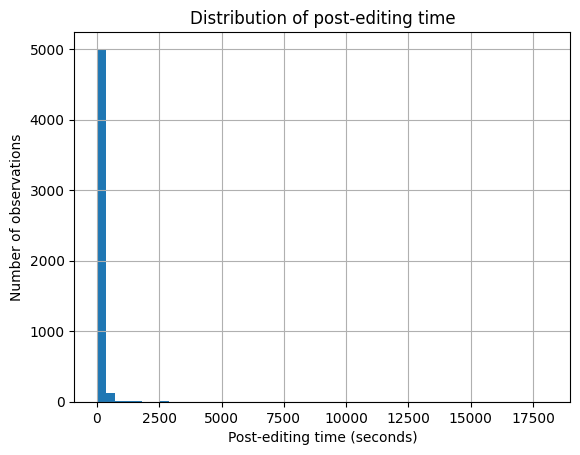

In [19]:
import matplotlib.pyplot as plt

pe["edit_time"].hist(bins=50)

plt.xlabel("Post-editing time (seconds)")
plt.ylabel("Number of observations")
plt.title("Distribution of post-editing time")
plt.show()

In [20]:
# Count observations and unique segments
summary = pe.groupby(
    ["lang_id", "task_type"]
).agg(
    observations=("unit_id", "size"),
    source_segments=("flores_id", "nunique"),
    documents=("doc_id", "nunique"),
    translators=("subject_id", "nunique")
)

display(summary)

observations  source_segments  documents  translators
lang_id task_type                                                       
ara     pe1                 430              430        107            3
        pe2                 430              430        107            3
ita     pe1                 430              430        107            3
        pe2                 430              430        107            3
nld     pe1                 430              430        107            3
        pe2                 430              430        107            3
tur     pe1                 430              430        107            3
        pe2                 430              430        107            3
ukr     pe1                 430              430        107            3
        pe2                 430              430        107            3
vie     pe1                 430              430        107            3
        pe2                 430              430        107            3

In [26]:
unique_mt = pe[
    ["lang_id", "src_text", "mt_text"]
].drop_duplicates()

print(
    "Total PE observations:",
    len(pe)
)

print(
    "Unique source-MT pairs (QE score is generated based on source+target):",
    len(unique_mt)
)

Total PE observations: 5160
Unique source-MT pairs (QE score is generated based on source+target): 5136


In [27]:
threshold = 45 * 60

long_edits = pe[pe["edit_time"] >= threshold]

print("Observations exceeding threshold based on divEMT paper:", len(long_edits))

display(
    long_edits.groupby(
        ["lang_id", "task_type"]
    ).size()
)

Observations exceeding threshold based on divEMT paper: 13


lang_id  task_type
ara      pe1          1
         pe2          1
vie      pe1          5
         pe2          6
dtype: int64

In [28]:
pair_cols = ["lang_id", "src_text", "mt_text"]

repeated_pairs = pe[
    pe.duplicated(subset=pair_cols, keep=False)
]

display(
    repeated_pairs[
        ["lang_id", "item_id", "doc_id",
         "task_type", "mt_text", "edit_time"]
    ].sort_values(
        ["lang_id", "item_id"]
    ).head(30)
)

print(
    "Repeated combinations spanning multiple documents:",
    (
        repeated_pairs.groupby(pair_cols)["doc_id"]
        .nunique() > 1
    ).sum()
)

,lang_id,item_id,doc_id,task_type,mt_text,edit_time
1355,ita,flores101-main-301,30,pe1,La cultura del lavoro giapponese è più gerarch...,16.899
1843,ita,flores101-main-301,30,pe2,La cultura del lavoro giapponese è più gerarch...,21.467
1416,ita,flores101-main-531,53,pe2,"Dopo l'incidente, Gibson è stato trasportato i...",37.963
2374,ita,flores101-main-531,53,pe1,"Dopo l'incidente, Gibson è stato trasportato i...",5.543
1434,ita,flores101-main-585,58,pe2,La polizia ha detto che il corpo sembrava esse...,22.485
2395,ita,flores101-main-585,58,pe1,La polizia ha detto che il corpo sembrava esse...,10.636
1453,ita,flores101-main-652,65,pe1,È il quinto CEP di Martelly in quattro anni.,8.361
1998,ita,flores101-main-652,65,pe2,È il quinto CEP di Martelly in quattro anni.,18.090
1499,ita,flores101-main-801,80,pe2,Naturalisti e filosofi si sono concentrati sui...,10.094
2489,ita,flores101-main-801,80,pe1,Naturalisti e filosofi si sono concentrati sui...,4.639


Repeated combinations spanning multiple documents: 0


In [29]:
pair_cols = ["lang_id", "src_text", "mt_text"]

repeated_pairs = pe[
    pe.duplicated(subset=pair_cols, keep=False)
]

cross_doc = (
    repeated_pairs
    .groupby(pair_cols)["doc_id"]
    .nunique()
)

print(
    "Source–MT pairs appearing in multiple documents:",
    (cross_doc > 1).sum()
)

Source–MT pairs appearing in multiple documents: 0
